# Risk & Return Metrics — Market Analytics Case Study

**Purpose:** turn the exploratory findings in `03_eda` into analyst-grade, per-stock risk/return metrics, and save a clean metrics table that feeds the Streamlit dashboard.

**Basket:** 18 US-listed stocks across Technology, Healthcare and Financial Services, daily prices from 2019-01-02 (split-adjusted).

### Metric definitions

| Metric | Definition | Why it matters |
|---|---|---|
| **Annualised return (simple)** | Mean daily return × 252 | Quick average-return measure; *overstates* growth for volatile stocks |
| **CAGR** | Compounded annual growth from first to last close | The return an investor who bought on day one actually earned |
| **Annualised volatility** | Std. dev. of daily returns × √252 | Size of typical swings |
| **Sharpe ratio** | (Return − risk-free rate) / volatility | Return earned per unit of risk |
| **Sharpe (CAGR basis)** | Same, using CAGR instead of the simple return | More conservative; accounts for volatility drag |
| **Max drawdown** | Worst peak-to-trough fall from a running high | Worst pain an investor would have sat through |

### Assumptions

- 252 trading days per year.
- Constant risk-free rate of 4% a year — a simplification (rates were near zero in 2019–2021). Replacing this with the actual Treasury bill series from FRED is a natural next step.
- Prices are split-adjusted (verified in `03_eda`).

## 1. Setup & Data Load

In [1]:
import os
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("../visuals", exist_ok=True)
os.makedirs("../data/processed", exist_ok=True)

TRADING_DAYS = 252
RISK_FREE_RATE = 0.04

conn = sqlite3.connect("../market_data.db")

query = """
SELECT prices.*, symbols.sector, symbols.sub_sector
FROM prices
JOIN symbols ON prices.ticker = symbols.ticker
"""
df = pd.read_sql(query, conn)
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values(["ticker", "date"]).reset_index(drop=True)
df["daily_return"] = df.groupby("ticker")["close"].pct_change()

print(f"{df.shape[0]:,} rows, {df['ticker'].nunique()} tickers, {df['date'].min().date()} to {df['date'].max().date()}")

33,820 rows, 18 tickers, 2019-01-02 to 2026-09-25


## 2. Per-Stock Risk & Return Metrics

### 2.1 Annualised return, volatility and Sharpe ratio

In [2]:
stats = df.groupby("ticker")["daily_return"].agg(["mean", "std"])

stats["ann_return"] = stats["mean"] * TRADING_DAYS
stats["ann_vol"] = stats["std"] * np.sqrt(TRADING_DAYS)
stats["sharpe"] = (stats["ann_return"] - RISK_FREE_RATE) / stats["ann_vol"]

stats.sort_values("sharpe", ascending=False)

,mean,std,ann_return,ann_vol,sharpe
ticker,,,,,
NVDA,0.002667,0.031787,0.672060,0.504611,1.252569
MU,0.002391,0.034030,0.602591,0.540213,1.041424
AMD,0.002423,0.035271,0.610476,0.559908,1.018875
LLY,0.001464,0.020706,0.369017,0.328701,1.000961
DDOG,0.001822,0.037915,0.459050,0.601875,0.696241
JPM,0.000916,0.018444,0.230868,0.292789,0.651896
KKR,0.001174,0.024859,0.295891,0.394626,0.648438
BX,0.001152,0.024547,0.290417,0.389676,0.642629
AXP,0.000890,0.021791,0.224388,0.345925,0.533028


**Finding — Sharpe ratio:** NVDA (1.25), MU (1.04), AMD (1.02) and LLY (1.00) lead the basket; BIIB (0.03) and ALHC (0.05) earned almost nothing for the risk taken. Financial Services names sit in a tight 0.35–0.65 band, consistent with how closely they move together. Technology (NVDA 1.25 vs CRM 0.28) and Healthcare (LLY 1.00 vs BIIB 0.03) each span almost the full range — sector is a poor guide to which stocks delivered.

*Annualisation note:* returns scale linearly with time (× 252) but volatility scales with the square root of time (× √252), because random daily moves partially offset one another.

### 2.2 Maximum drawdown

In [3]:
df["running_peak"] = df.groupby("ticker")["close"].cummax()
df["drawdown"] = (df["close"] - df["running_peak"]) / df["running_peak"]

max_dd = df.groupby("ticker")["drawdown"].min()
max_dd.sort_values()

ticker
ALHC   -0.836084
SNOW   -0.729876
BIIB   -0.726604
MOH    -0.707649
DDOG   -0.681064
NVDA   -0.663351
AMD    -0.654499
UNH    -0.613909
WFC    -0.598065
CRM    -0.586696
MU     -0.576290
AXP    -0.496385
KKR    -0.494162
BX     -0.492861
JPM    -0.436265
V      -0.363649
LLY    -0.344750
NVS    -0.260332
Name: drawdown, dtype: float64

**Finding — drawdown:** the shallowest worst-case losses are NVS (−26%), LLY (−34%) and V (−36%); the deepest are ALHC (−84%), SNOW (−73%) and BIIB (−73%). Note that **NVDA has the best Sharpe ratio yet still suffered a −66% drawdown** — a strong risk-adjusted return does not mean a smooth ride, which is why both measures are reported. UNH's −61% is consistent with the repeated large negative outlier days found in `03_eda`.

*Caveat:* the running peak is measured from the start of each stock's available history, so a stock already well below an earlier high before 2019 (or before its IPO) would not show that fall.

### 2.3 Compounded return (CAGR)

Sharpe above uses the *arithmetic* average return, which flatters volatile stocks: a stock that falls 50% and then rises 50% is down 25%, not flat. CAGR measures what a buy-and-hold investor actually earned.

In [4]:
years = df.groupby("ticker")["date"].agg(lambda d: (d.max() - d.min()).days / 365.25)
first_close = df.groupby("ticker")["close"].first()
last_close = df.groupby("ticker")["close"].last()

cagr = ((last_close / first_close) ** (1 / years) - 1) * 100
cagr.sort_values(ascending=False).round(1)

ticker
NVDA    72.2
MU      57.7
AMD     57.5
LLY     37.0
DDOG    32.3
KKR     24.3
BX      23.8
JPM     20.6
AXP     17.9
V       14.9
NVS     13.1
WFC     10.6
UNH      7.7
CRM      7.6
MOH      7.0
SNOW     4.8
BIIB    -3.7
ALHC   -12.7
dtype: float64

**Finding — volatility drag:** ALHC and BIIB are **negative compounders** (−12.7% and −3.7% a year) even though their simple annualised returns are positive (+7.6% and +5.5%). The gap between the two measures is roughly half the variance, so it is largest for the most volatile stocks (ALHC ≈ 20 points, SNOW ≈ 19, DDOG ≈ 14). NVDA is the one exception, where CAGR (72.2%) *exceeds* the simple figure (67.2%): at very high average returns, scaling by 252 understates compounding by more than the drag takes away.

*Caveats:* CAGR depends on its start and end dates, and SNOW's history begins on its IPO day, after the first-day price jump, which depresses its figure. The three short-history names (SNOW, DDOG, ALHC) cover different windows from the rest and are not strictly comparable.

## 3. Consolidated Metrics Table

Combines every metric into one table (percentages), including a Sharpe ratio recalculated on a CAGR basis. This is the file the dashboard reads.

In [5]:
sector_lookup = df[["ticker", "sector", "sub_sector"]].drop_duplicates().set_index("ticker")

metrics = (
    stats[["ann_return", "ann_vol", "sharpe"]]
    .join(max_dd.rename("max_drawdown"))
    .join(sector_lookup)
)
metrics["ann_return"] *= 100
metrics["ann_vol"] *= 100
metrics["max_drawdown"] *= 100

metrics["cagr"] = cagr
metrics["sharpe_cagr"] = (metrics["cagr"] - RISK_FREE_RATE * 100) / metrics["ann_vol"]
metrics["years_of_data"] = years

metrics = metrics[["sector", "sub_sector", "years_of_data", "ann_return", "cagr", "ann_vol",
                   "sharpe", "sharpe_cagr", "max_drawdown"]]
metrics = metrics.round(2).sort_values("sharpe_cagr", ascending=False)

metrics.to_csv("../data/processed/risk_metrics.csv")
metrics

,sector,sub_sector,years_of_data,ann_return,cagr,ann_vol,sharpe,sharpe_cagr,max_drawdown
ticker,,,,,,,,,
NVDA,Technology,Semiconductors,7.73,67.21,72.23,50.46,1.25,1.35,-66.34
LLY,Healthcare,Drug Manufacturers,7.73,36.90,36.97,32.87,1.00,1.00,-34.48
MU,Technology,Semiconductors,7.73,60.26,57.75,54.02,1.04,0.99,-57.63
AMD,Technology,Semiconductors,7.73,61.05,57.51,55.99,1.02,0.96,-65.45
JPM,Financial Services,Banks,7.73,23.09,20.64,29.28,0.65,0.57,-43.63
BX,Financial Services,Asset Management,7.73,29.04,23.84,38.97,0.64,0.51,-49.29
KKR,Financial Services,Asset Management,7.73,29.59,24.29,39.46,0.65,0.51,-49.42
DDOG,Technology,Software,7.02,45.91,32.33,60.19,0.70,0.47,-68.11
NVS,Healthcare,Drug Manufacturers,7.73,14.55,13.11,20.89,0.50,0.44,-26.03


**Finding — ranking on a compounded basis:** the top four hold (NVDA, LLY, MU, AMD), so the leaders are robust to the choice of measure. The lower end changes: SNOW falls to roughly zero, and ALHC and BIIB turn negative. LLY is the standout combination — a Sharpe around 1.0 with the second-shallowest drawdown in the basket.

**Important:** NVDA, MU and AMD are the semiconductor cluster identified in the correlation analysis (≈0.57 pairwise). They represent largely **one** AI/chips theme appearing three times, not three independent results.

## 4. Volatility Over Time

The full-period figures above hide how risk changed through time. A 60-day rolling window shows it directly.

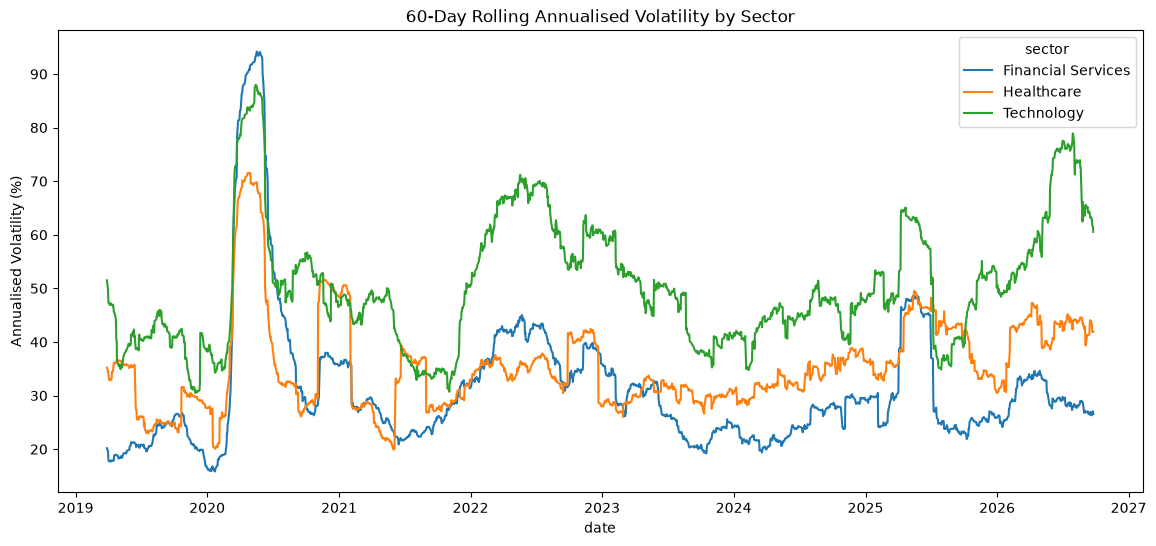

In [6]:
df["rolling_vol_60d"] = (
    df.groupby("ticker")["daily_return"]
    .transform(lambda s: s.rolling(60).std())
    * np.sqrt(TRADING_DAYS) * 100
)

sector_roll_vol = df.groupby(["date", "sector"])["rolling_vol_60d"].mean().reset_index()

plt.figure(figsize=(14, 6))
sns.lineplot(data=sector_roll_vol, x="date", y="rolling_vol_60d", hue="sector")
plt.title("60-Day Rolling Annualised Volatility by Sector")
plt.ylabel("Annualised Volatility (%)")
plt.savefig("../visuals/rolling_volatility_by_sector.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding — rolling volatility:** volatility is not constant — it spikes sharply across all sectors during market stress, most visibly in March 2020, and Technology generally runs above Financial Services, consistent with the full-period results. The sector line is the average of its stocks' rolling volatility, so it shifts slightly as SNOW, DDOG and ALHC enter the sample after their IPOs, and the first 60 days of each stock have no value.

## 5. Drawdown Over Time

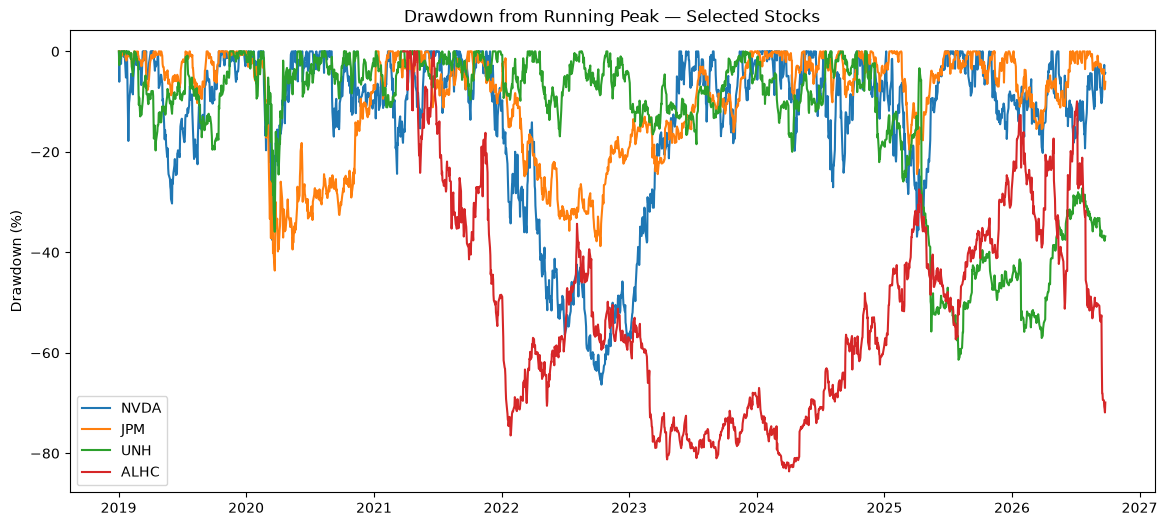

In [7]:
plt.figure(figsize=(14, 6))
for t in ["NVDA", "JPM", "UNH", "ALHC"]:
    subset = df[df["ticker"] == t]
    plt.plot(subset["date"], subset["drawdown"] * 100, label=t)

plt.title("Drawdown from Running Peak — Selected Stocks")
plt.ylabel("Drawdown (%)")
plt.legend()
plt.savefig("../visuals/drawdown_selected.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:** four stocks chosen to span the range — NVDA (−66% worst), JPM (−44%), UNH (−61%) and ALHC (−84%). Each line sits at zero at a new high and falls during declines, so the chart shows both how deep and how long each stock's worst stretch lasted. ALHC spends most of the period far below its peak, which is what a negative CAGR looks like.

## 6. Risk vs. Return

CAGR (not the simple average) is plotted so the negative compounders appear honestly. The dashed line marks zero, and the dotted line marks the 4% risk-free rate — anything below it was beaten by a Treasury bill.

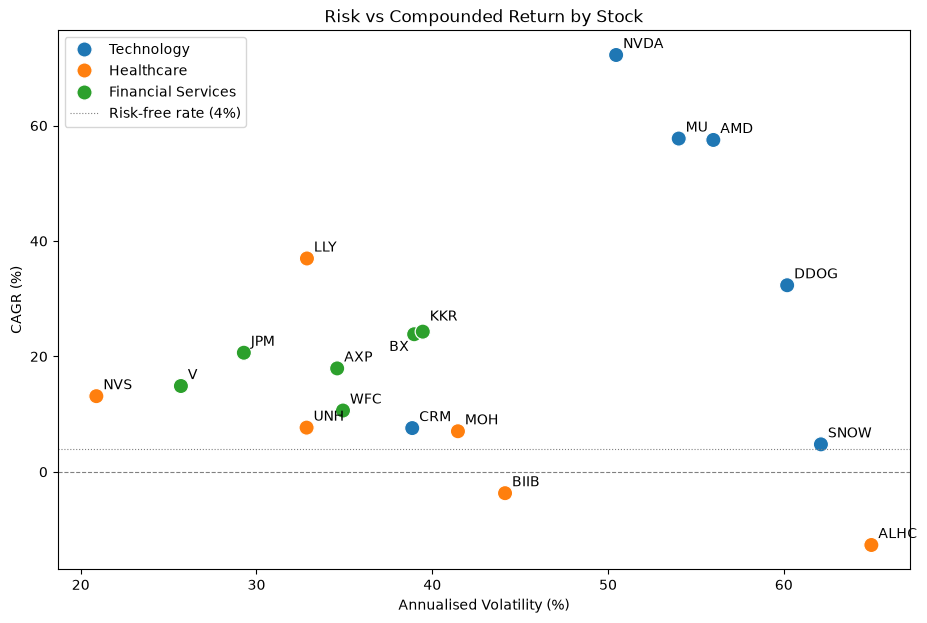

In [8]:
plot_df = metrics.reset_index()

offsets = {"KKR": (5, 8), "BX": (-18, -12)}  # manual offsets for overlapping labels

plt.figure(figsize=(11, 7))
sns.scatterplot(data=plot_df, x="ann_vol", y="cagr", hue="sector", s=120)
for _, row in plot_df.iterrows():
    dx, dy = offsets.get(row["ticker"], (5, 5))
    plt.annotate(row["ticker"], (row["ann_vol"], row["cagr"]), xytext=(dx, dy), textcoords="offset points")

plt.axhline(0, color="gray", linestyle="--", linewidth=0.8)
plt.axhline(RISK_FREE_RATE * 100, color="gray", linestyle=":", linewidth=0.8, label="Risk-free rate (4%)")
plt.xlabel("Annualised Volatility (%)")
plt.ylabel("CAGR (%)")
plt.title("Risk vs Compounded Return by Stock")
plt.legend()
plt.savefig("../visuals/risk_return_cagr.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:** LLY sits alone in the favourable upper-left — a higher return than any Financial Services name at lower volatility than most of them. The semiconductors cluster top-right (high return, high risk), and ALHC, SNOW and BIIB fall in the worst region (high risk, return at or below the risk-free rate). Financial Services forms a tight middle cluster, Technology is spread across the whole chart, and Healthcare spans both extremes — the "sector label is a weak predictor" finding from `03_eda`, now visible in a single picture.

## Summary of Key Findings

1. **NVDA, LLY, MU and AMD lead on every risk-adjusted measure**, on both the simple and compounded basis — though NVDA, MU and AMD are one correlated semiconductor cluster, effectively a single theme.
2. **A high Sharpe ratio does not imply a shallow drawdown** — NVDA has the best Sharpe yet a −66% worst fall.
3. **LLY is the best combination of return and downside protection**: Sharpe around 1.0 with the second-shallowest drawdown (−34%).
4. **ALHC and BIIB are negative compounders** (−12.7% and −3.7% a year) despite positive average daily returns — volatility drag. Arithmetic-mean Sharpe overstates volatile stocks, so a CAGR-based Sharpe is reported alongside.
5. **Financial Services is tightly clustered** (Sharpe 0.35–0.65, CAGR 11–24%), while Technology and Healthcare each span nearly the full range — sector is a weak predictor of outcomes.
6. **Risk is not constant**: rolling volatility spikes across sectors in stress periods, so a single full-period figure understates risk at the worst moments.

### Limitations

- **Hindsight selection:** the basket was chosen with knowledge of well-known names, so these are descriptive results for this basket and period, not evidence about which stocks to buy.
- **Constant 4% risk-free rate:** simplifies a period when rates ranged from near zero to over 5%.
- **Unequal histories:** SNOW, DDOG and ALHC cover shorter windows, so their metrics are not directly comparable with the rest.
- **Endpoint sensitivity:** CAGR and max drawdown depend on the exact window; results describe 2019 to date, not a general ranking.